# 16.6 - Alignment validation error audit

Compare the three saved checkpoints on the same source validation images. Source labels describe occlusal views and are incomplete as a measure of frontal phone performance. Matching uses class-aware IoU >= 0.50 and confidence >= 0.25. Unmatched predictions are possible false positives, not confirmed errors.

In [1]:
from pathlib import Path
import zipfile, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from ultralytics import YOLO
root = Path.cwd().resolve()
while not (root / "AGENTS.md").exists(): root = root.parent
os.chdir(root)
archive = root / ".venv/work/kaggle/alignment_occlusal_data/alignment_occlusal.zip"
work = root / ".venv/work/alignment_audit_16_6"
work.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(archive) as z:
    files = [x for x in z.namelist() if x.startswith(("images/val/", "labels/val/")) and not x.endswith("/")]
    z.extractall(work, members=files)
images = sorted((work / "images/val").glob("*"))
print("Validation images:", len(images))

Validation images: 38


## Load checkpoints and inspect predictions

All three models use the same image set and confidence threshold. The 960 experiment retains its training inference size; results are descriptive, not a controlled resolution ablation.

In [2]:
models = {"n640": ("data/runs/alignment_occlusal_v1/runs/occlusal_yolo11n/weights/best.pt", 640), "s640": ("data/runs/alignment_s_v1/runs/occlusal_s/weights/best.pt", 640), "n960": ("data/runs/alignment_n960_v1/runs/occlusal_n960/weights/best.pt", 960)}
predictions = {}
for name, (path, size) in models.items():
    model = YOLO(str(root / path))
    predictions[name] = list(model.predict([str(p) for p in images], imgsz=size, conf=0.25, device="cpu", verbose=False, stream=True))
    print(name, len(predictions[name]), "images")

n640 38 images


s640 38 images


n960 38 images


## Match predictions to source annotations

Greedy matching sorts predictions by confidence and matches each to the highest-IoU unused annotation of the same class. Source omissions and ambiguous boxes require manual review.

In [3]:
def iou(a, b):
    x1,y1=np.maximum(a[:2],b[:2]); x2,y2=np.minimum(a[2:],b[2:]); inter=max(0,x2-x1)*max(0,y2-y1)
    return inter / max(1e-9,(a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-inter)
rows=[]
for idx, image in enumerate(images):
    w,h=Image.open(image).size
    label=work / "labels/val" / (image.stem+".txt")
    gt=[]
    for line in label.read_text().splitlines() if label.exists() else []:
        cl,x,y,bw,bh=map(float,line.split()); gt.append((int(cl),np.array([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h])))
    for name in models:
        boxes=predictions[name][idx].boxes
        used=set(); matches=0
        for p in sorted(boxes, key=lambda q: -float(q.conf[0])):
            cls=int(p.cls[0]); xy=p.xyxy[0].numpy(); choices=[(iou(xy,g),j) for j,(gc,g) in enumerate(gt) if gc==cls and j not in used]
            score,j=max(choices,default=(0,-1))
            if score>=0.5: used.add(j); matches+=1
        rows.append(dict(image=image.name,model=name,ground_truth=len(gt),matched=matches,missed=len(gt)-matches,unmatched_predictions=len(boxes)-matches))
results=pd.DataFrame(rows)
summary=results.groupby("model")[["ground_truth","matched","missed","unmatched_predictions"]].sum()
display(summary)

,ground_truth,matched,missed,unmatched_predictions
model,,,,
n640,42,32,10,26
n960,42,26,16,12
s640,42,32,10,29


## Review difficult images

Images with most missed or unmatched boxes are shown with source boxes in green and model predictions in red. A visual discrepancy is a review candidate, not a clinical conclusion.

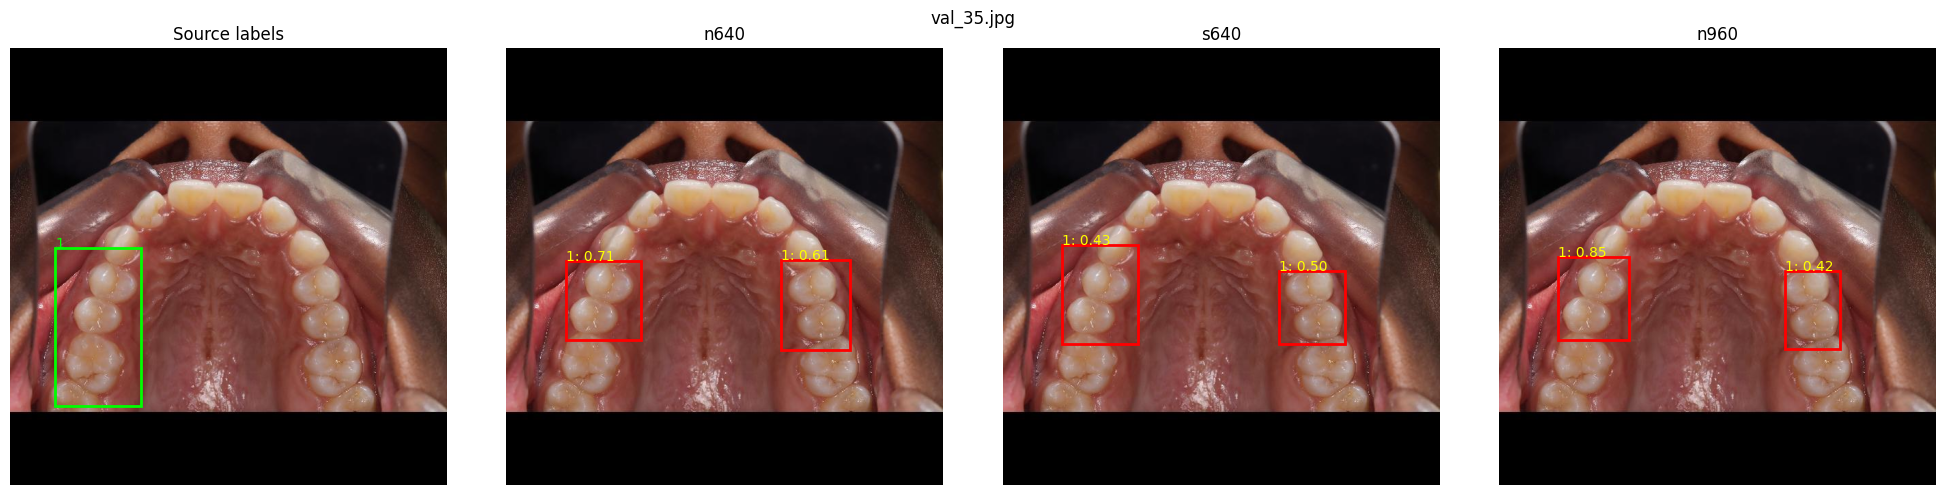

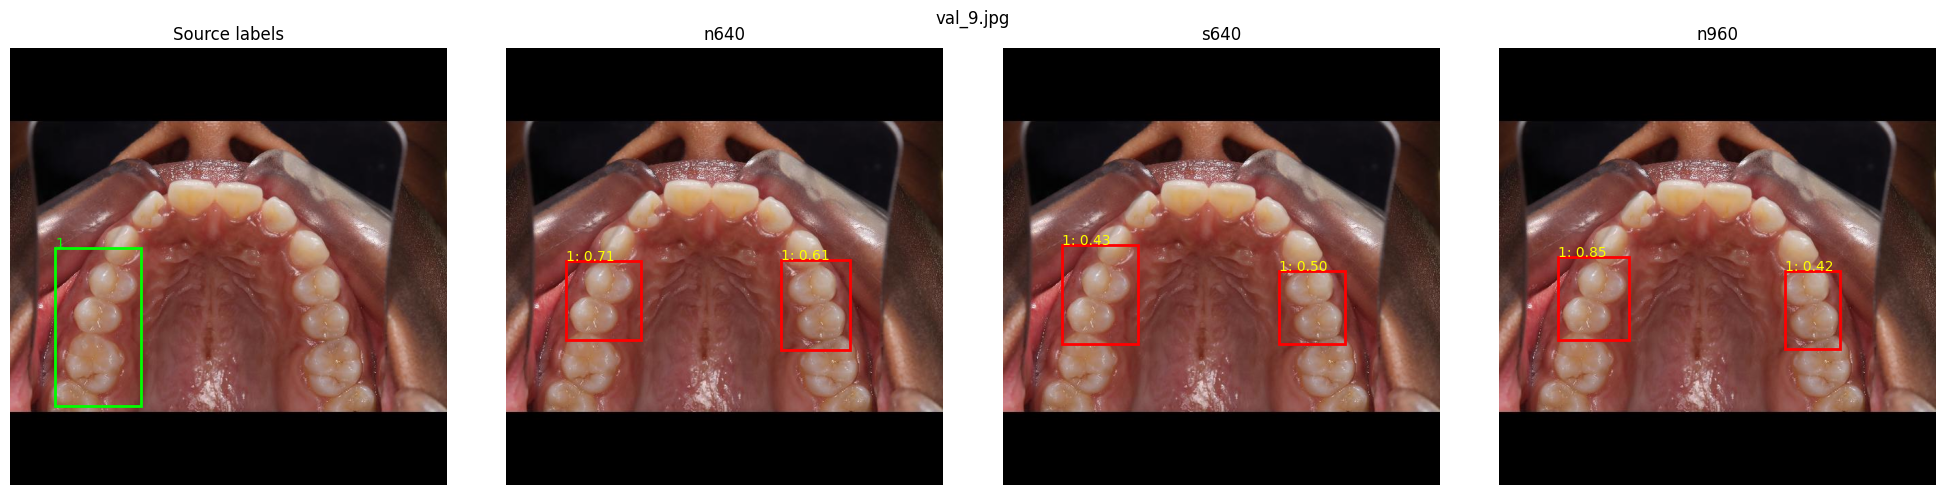

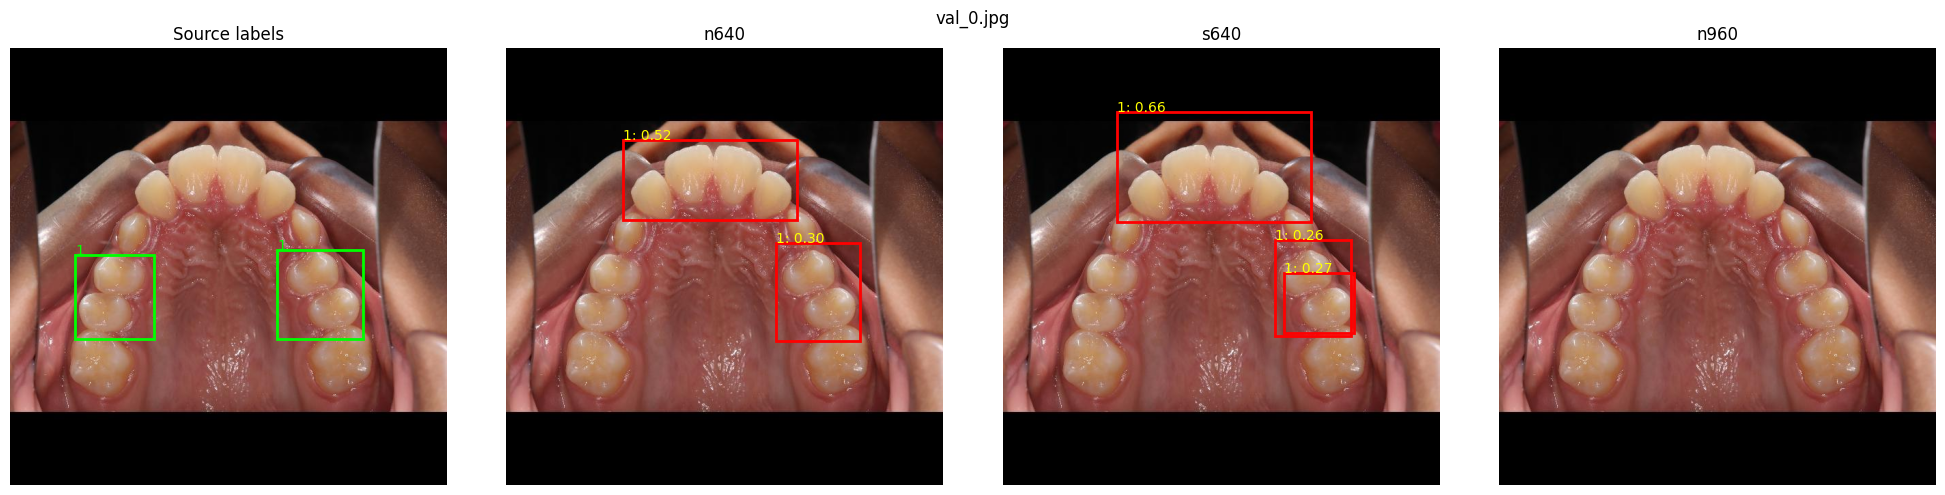

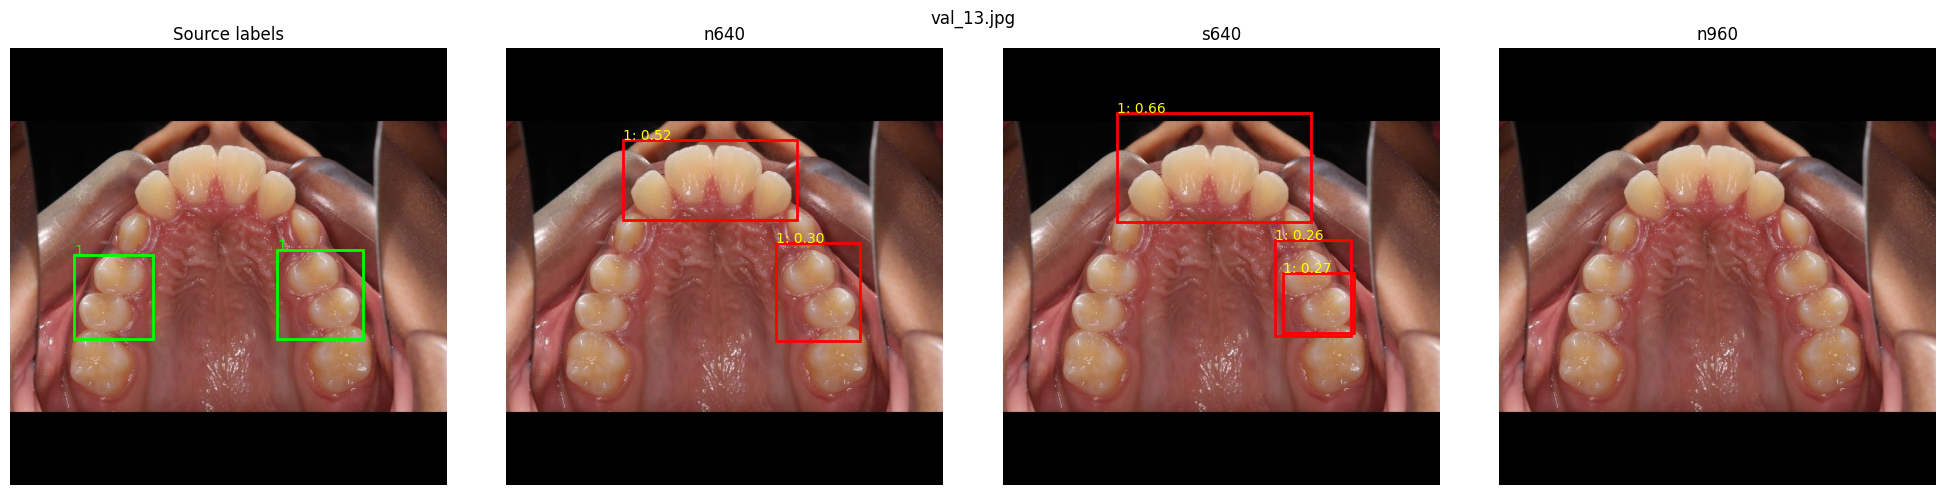

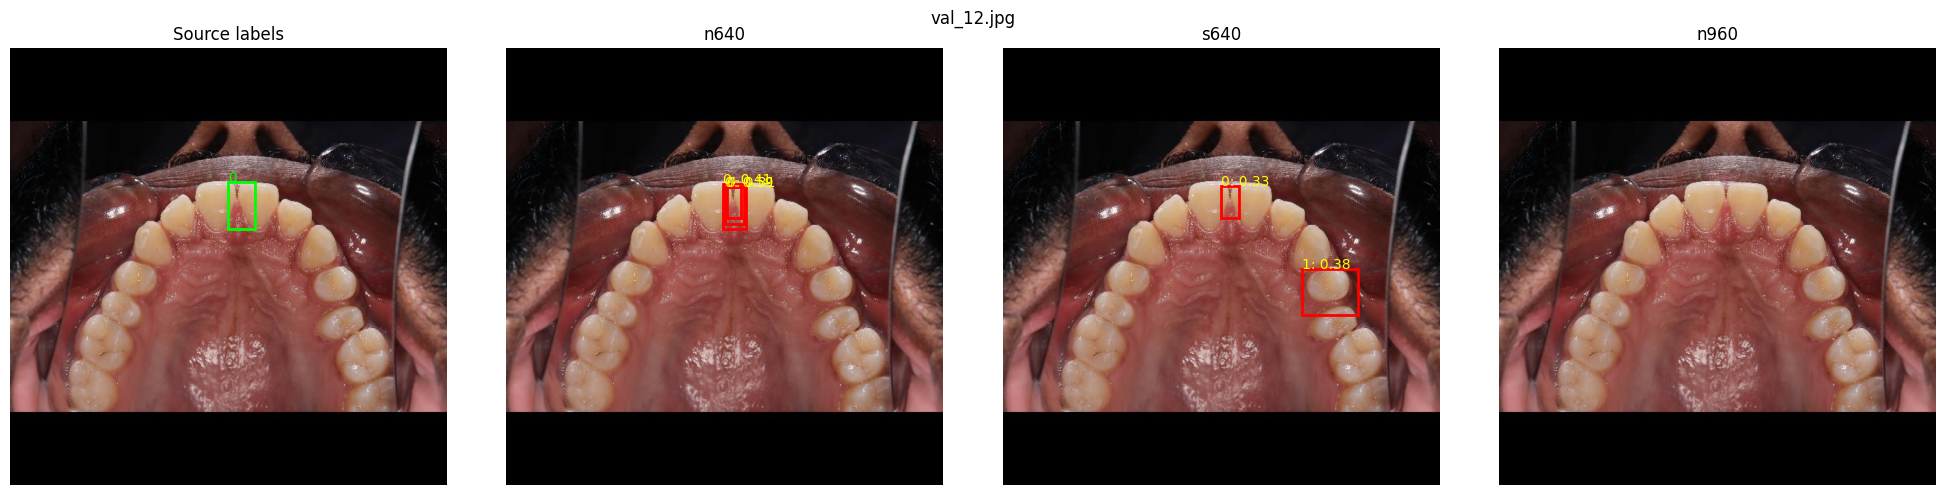

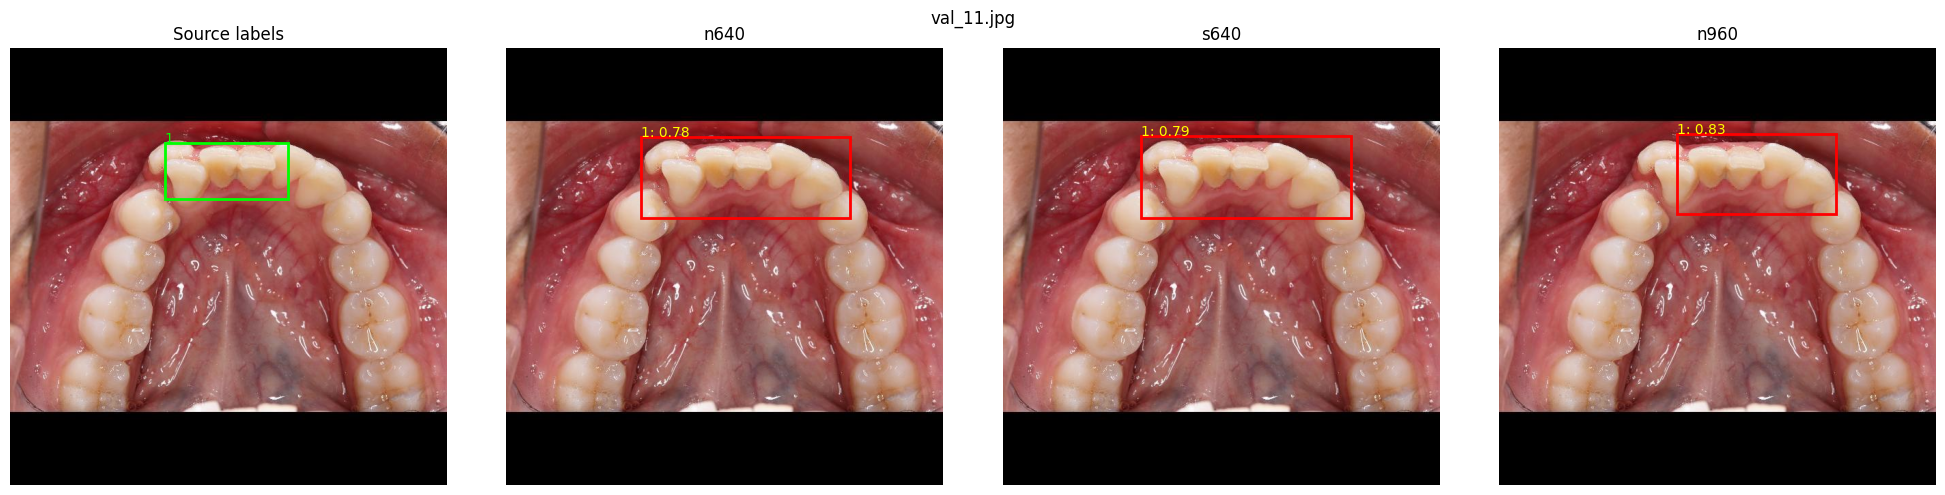

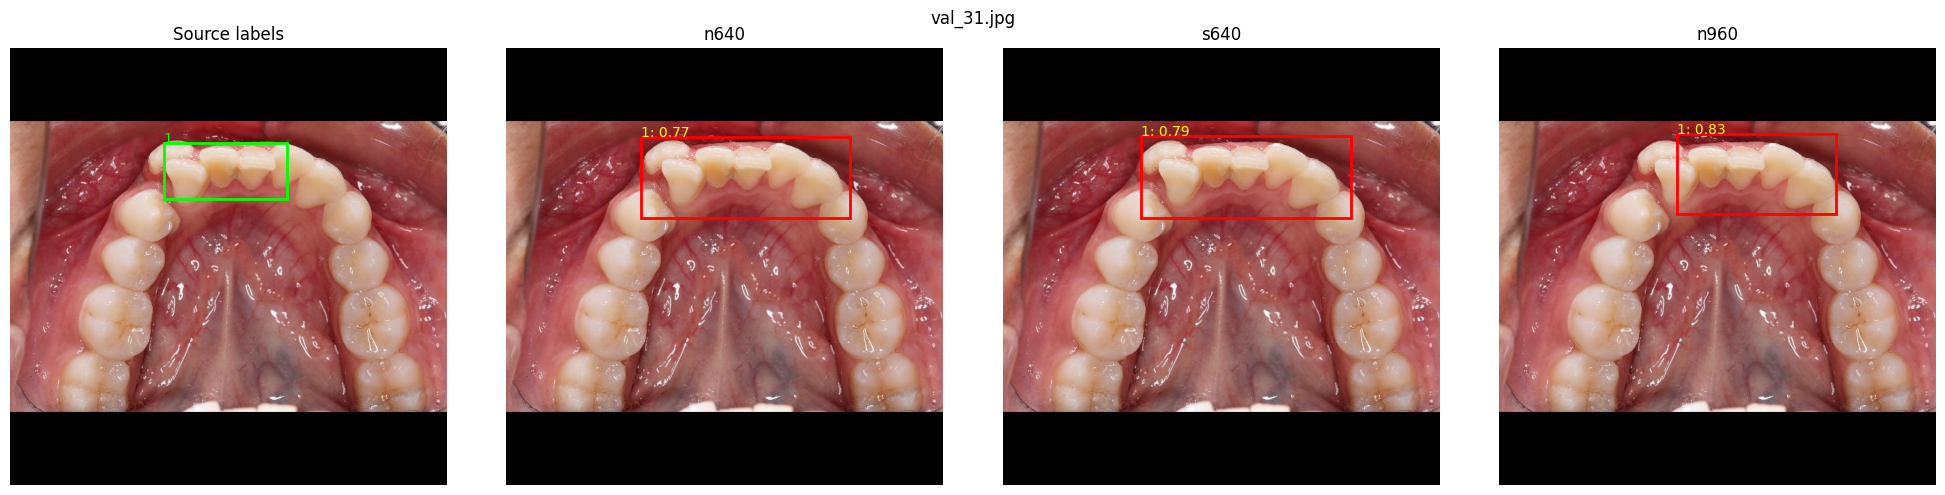

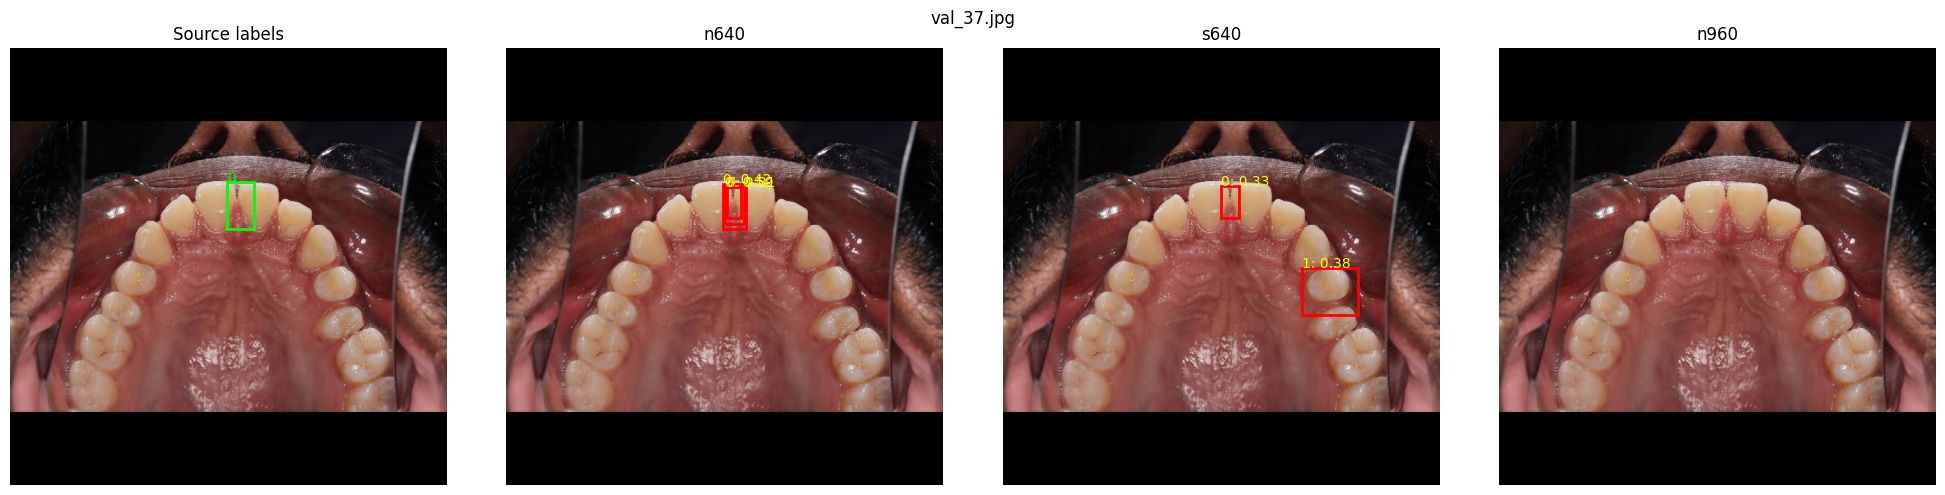

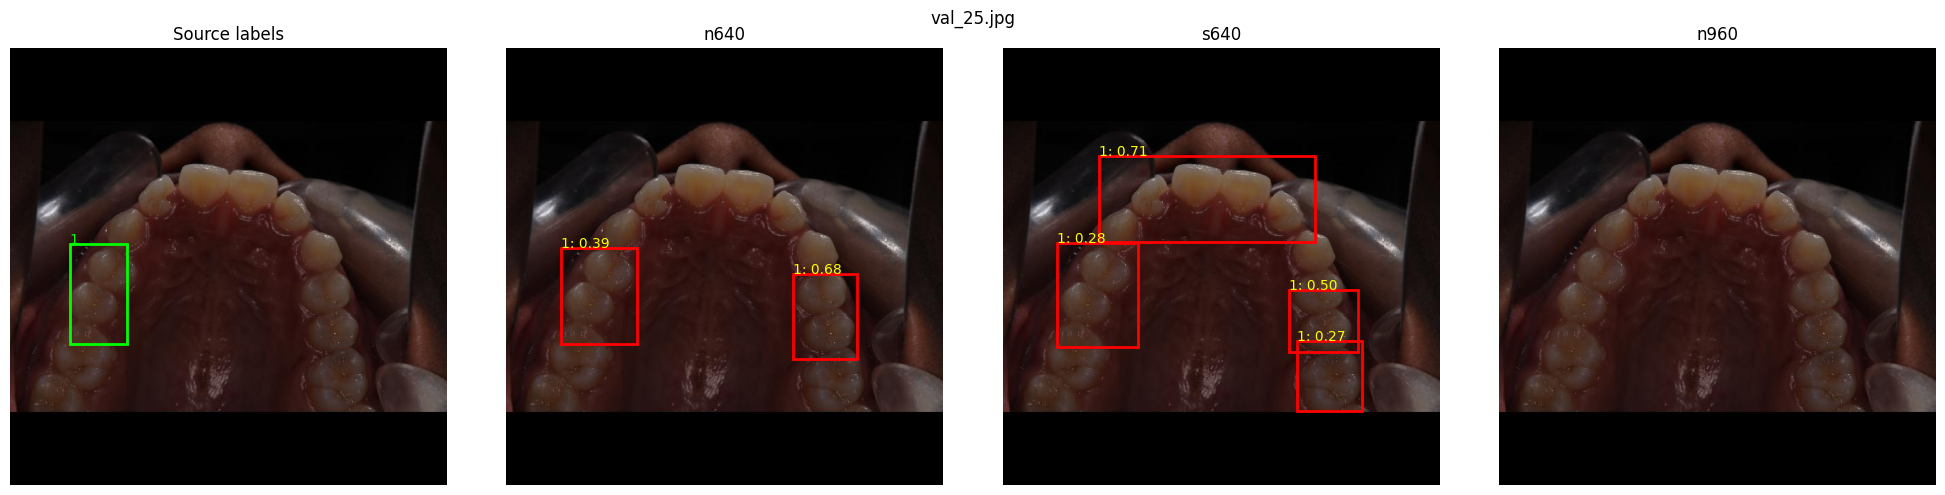

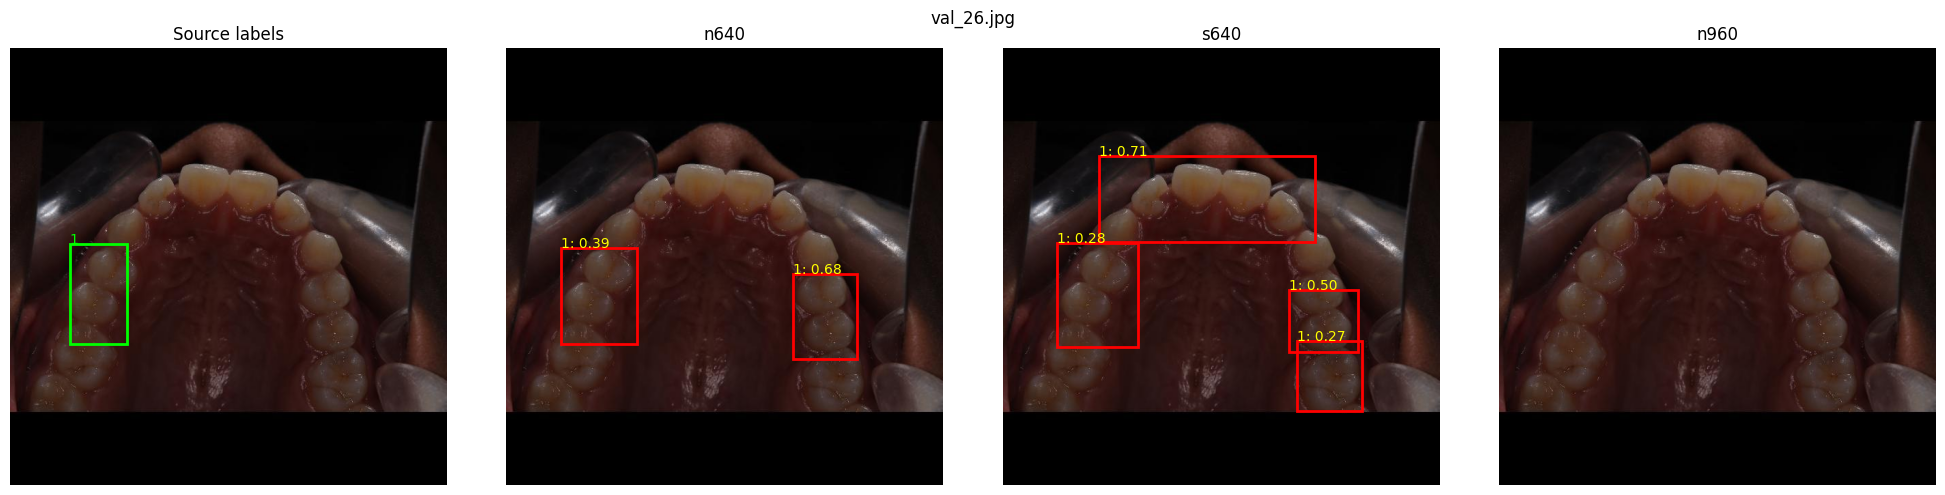

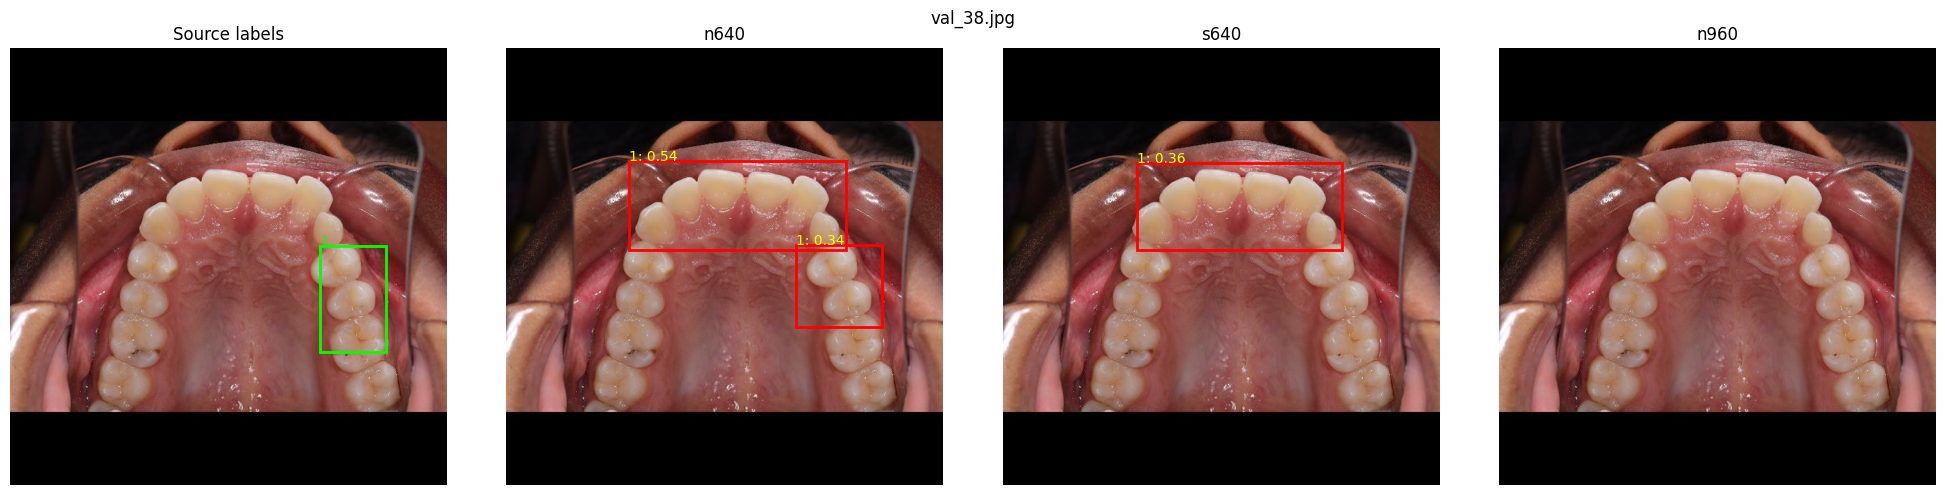

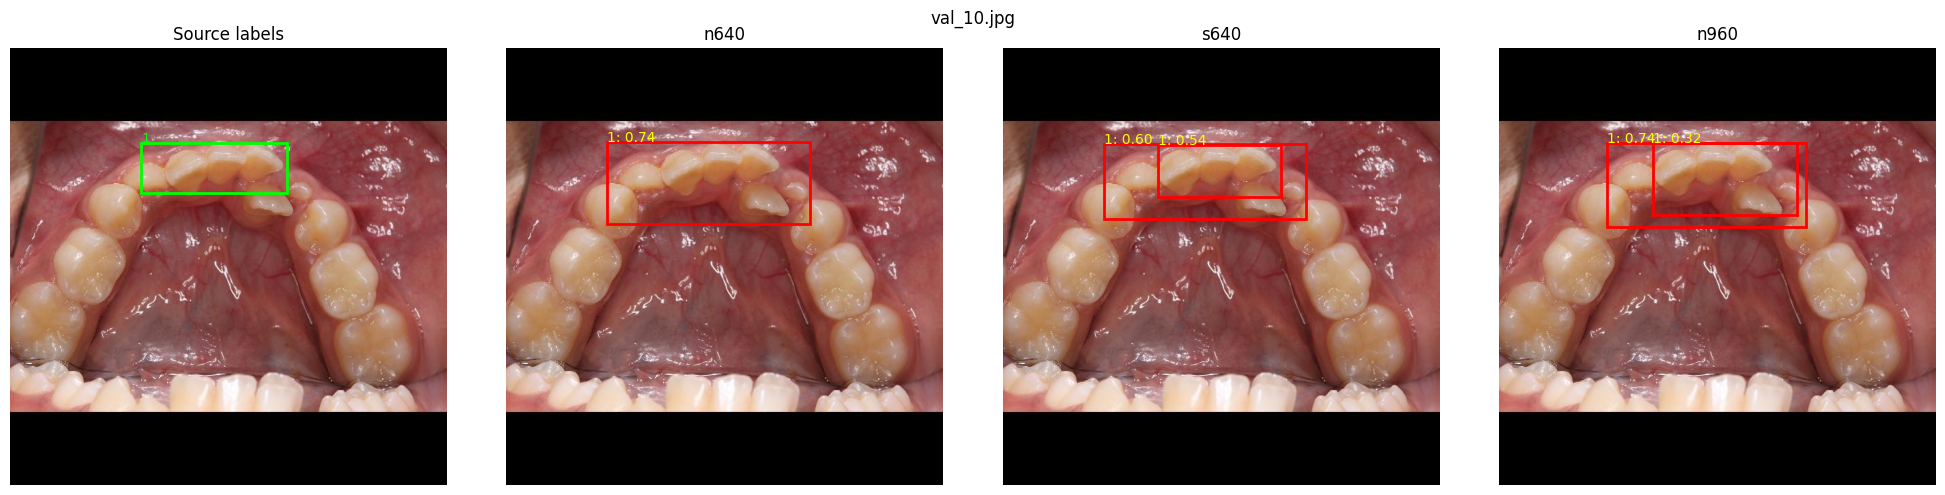

Saved audit to C:\Users\huynh\Desktop\oral-disease\docs\reports\alignment\audit_16_6


In [4]:
out=root / "docs/reports/alignment/audit_16_6"
out.mkdir(parents=True,exist_ok=True)
results.to_csv(out / "per_image.csv",index=False)
summary.to_csv(out / "summary.csv")
rank=results.groupby("image").apply(lambda x: (x.missed+x.unmatched_predictions).sum(),include_groups=False).sort_values(ascending=False)
for filename in rank.head(12).index:
    idx=next(i for i,p in enumerate(images) if p.name==filename); path=images[idx]; image=Image.open(path).convert("RGB"); w,h=image.size
    fig,axes=plt.subplots(1,4,figsize=(20,5)); axes[0].imshow(image); axes[0].set_title("Source labels")
    label=work / "labels/val" / (path.stem+".txt")
    for line in label.read_text().splitlines() if label.exists() else []:
        cl,x,y,bw,bh=map(float,line.split()); axes[0].add_patch(plt.Rectangle(((x-bw/2)*w,(y-bh/2)*h),bw*w,bh*h,fill=False,color="lime",linewidth=2)); axes[0].text((x-bw/2)*w,(y-bh/2)*h,str(int(cl)),color="lime")
    for ax,(name,_) in zip(axes[1:],models.items()):
        ax.imshow(image); ax.set_title(name)
        for p in predictions[name][idx].boxes:
            x1,y1,x2,y2=p.xyxy[0].tolist(); ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color="red",linewidth=2)); ax.text(x1,y1,f"{int(p.cls[0])}: {float(p.conf[0]):.2f}",color="yellow")
    for ax in axes: ax.axis("off")
    fig.suptitle(filename); fig.tight_layout(); fig.savefig(out / (path.stem+".png"),dpi=100); plt.show(); plt.close(fig)
print("Saved audit to",out)